In [2]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal

print("Installations Working!")

Installations Working!


### Parameter Setup

In [3]:
prior_0 = .6
prior_1 = .4

dist_weight = .5

mu_01 = [-.9, -1.1]
mu_02 = [.8, .75]
mu_11 = [-1.1, .9]
mu_12 = [.9, -.75]

cov = [[.75, 0], [0, 1.25]]

def g(mu, C, X_dist):
    return multivariate_normal(mu, C).pdf(X_dist)

def make_dist(sample_size):

    rng = np.random.default_rng(42)
    L = (rng.random(sample_size) < prior_1).astype(int)   # 1 with prob 0.4, else 0
    n1 = np.sum(L == 1)
    n0 = np.sum(L == 0)

    print(f"Label 0: {n0} | Label 1: {n1}")

    n0_1 = int(n0 * dist_weight)
    n0_2 = int(n0 * dist_weight)

    n1_1 = int(n1 * dist_weight)
    n1_2 = int(n1 * dist_weight)

    if (n1_1 + n1_2 < n1):
        n1_1 += 1

    if ((n0_1 + n0_2 < n0)):
        n0_1 += 1

    dist_01 = rng.multivariate_normal(mu_01, cov, size=n0_1)
    dist_02 = rng.multivariate_normal(mu_02, cov, size=n0_2)
    dist_11 = rng.multivariate_normal(mu_11, cov, size=n1_1)
    dist_12 = rng.multivariate_normal(mu_12, cov, size=n1_2)



    X_dist = np.vstack([dist_01, dist_02, dist_11, dist_12])
    L = np.concatenate([np.zeros(n0, dtype=int), np.ones(n1, dtype=int)])

    # Verification


    return L, X_dist

In [4]:
L_20, X_20 = make_dist(20)
L_200, X_200 = make_dist(200)
L_2000, X_2000 = make_dist(2000)
L_10000, X_10000 = make_dist(10000)


Label 0: 15 | Label 1: 5
Label 0: 121 | Label 1: 79
Label 0: 1211 | Label 1: 789
Label 0: 5966 | Label 1: 4034


## Part 1


In [5]:
gamma = prior_0 / prior_1


# ERM Classifier

scores = np.stack([
    (.5 * g(mu_01, cov, X_10000) + .5* g(mu_02, cov, X_10000)) * prior_0,
    (.5 * g(mu_11, cov, X_10000) + .5* g(mu_12, cov, X_10000)) * prior_1,
], axis=1)

D = np.argmax(scores, axis=1)


print(scores)

print(f"Accuracy: {np.mean(D == L_10000)}")


scores

[[0.00448488 0.00189547]
 [0.02415712 0.02742538]
 [0.04445478 0.01702809]
 ...
 [0.02453228 0.01495329]
 [0.00602438 0.02050841]
 [0.00013692 0.00228801]]
Accuracy: 0.72


array([[0.00448488, 0.00189547],
       [0.02415712, 0.02742538],
       [0.04445478, 0.01702809],
       ...,
       [0.02453228, 0.01495329],
       [0.00602438, 0.02050841],
       [0.00013692, 0.00228801]], shape=(10000, 2))

Best Theoretical Error: 
Gamma: 1.4999999999999998
TPR: 0.526524541398116 FPR: 0.1491786791820315
Best Estimated Error: 
Gamma: 0.4647234567923464
TPR: 0.5123946455131383 FPR: 0.13627220918538385 


C:\Users\ronan\AppData\Local\Temp\ipykernel_23528\2265518657.py:61: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bs" (-> color='b'). The keyword argument will take precedence.
  plt.plot(emp_full_fpr, emp_full_tpr, 'bs', markersize=5, color='blue', label=f'Empirical Min Error: {round((emperical_error), 4)}  @ γ = {round(np.exp(emp_gamma), 2)}')


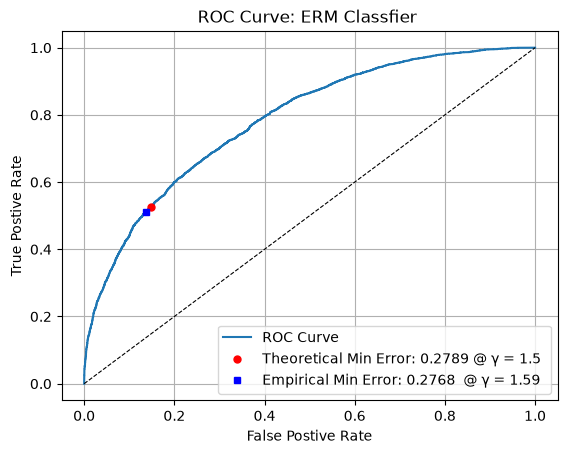

In [6]:
# ROC Curve Building
def class_likelihoods(X):
    p0 = 0.5 * g(mu_01, cov, X) + 0.5 * g(mu_02, cov, X)
    p1 = 0.5 * g(mu_11, cov, X) + 0.5 * g(mu_12, cov, X)
    return p0, p1

p0, p1 = class_likelihoods(X_10000)
llr = np.log(p1) - np.log(p0)   


thresholds = np.concatenate([[-np.inf], np.sort(llr), [np.inf]])

TPR, FPR = [], []

Gamma_map = dict()

for threshold in thresholds:
    Decision = llr > threshold
    TPR.append(np.mean(Decision[L_10000 == 1])) # P(D=1 | L=1)
    FPR.append(np.mean(Decision[L_10000 == 0])) # P(D=1 | L=0)
    Gamma_map[threshold] = (np.mean(Decision[L_10000 == 1]), np.mean(Decision[L_10000 == 0]))

# Theoretical Minimum Error

D = llr > np.log(gamma)
X_10k_theo_fpr = np.mean(D[L_10000 == 0])
X_10k_theo_tpr = np.mean(D[L_10000 == 1])
theory_error = X_10k_theo_fpr * prior_0 + (1 - X_10k_theo_tpr) * prior_1

print(f"Best Theoretical Error: ")
print(f"Gamma: {gamma}")
print(f"TPR: {X_10k_theo_tpr} FPR: {X_10k_theo_fpr}")


# Estimation of Lowest Error

error = np.inf
for t in thresholds:
    tpr, fpr = Gamma_map[t] 
    new_error = fpr * prior_0 + (1-tpr) * prior_1

    if new_error < error:
        error = new_error
        emp_gamma = t
        emp_full_tpr = tpr
        emp_full_fpr = fpr

print(f"Best Estimated Error: ")
print(f"Gamma: {emp_gamma}")
print(f"TPR: {emp_full_tpr} FPR: {emp_full_fpr} ")
emperical_error = (emp_full_fpr * prior_0 + (1 - emp_full_tpr) * prior_1) 



# Plotting

plt.plot(FPR, TPR, label = "ROC Curve")

plt.plot(X_10k_theo_fpr,X_10k_theo_tpr, 'ro', markersize=5, label=f'Theoretical Min Error: {round(theory_error, 4)} @ γ = {round(gamma, 2)} ')

plt.plot(emp_full_fpr, emp_full_tpr, 'bs', markersize=5, color='blue', label=f'Empirical Min Error: {round((emperical_error), 4)}  @ γ = {round(np.exp(emp_gamma), 2)}')

plt.plot([0, 1], [0, 1], 'k--', linewidth=0.8)

plt.title("ROC Curve: ERM Classfier ")
plt.xlabel("False Postive Rate")
plt.ylabel("True Postive Rate")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
from matplotlib.lines import Line2D

# Grid covering the validation data
pad = 0.5
x_min, x_max = X_10000[:, 0].min() - pad, X_10000[:, 0].max() + pad
y_min, y_max = X_10000[:, 1].min() - pad, X_10000[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
grid = np.column_stack([xx.ravel(), yy.ravel()])

# Log-likelihood ratio on the grid; boundary is where it equals ln(gamma)
p0_g, p1_g = class_likelihoods(grid)
llr_grid = (np.log(p1_g) - np.log(p0_g)).reshape(xx.shape)

correct = (D == L_10000)
err = 1 - np.mean(correct)

fig, ax = plt.subplots(figsize=(8, 7))

# Shaded decision regions + boundary
ax.contourf(xx, yy, llr_grid, levels=[llr_grid.min(), np.log(gamma), llr_grid.max()],
            colors=['tab:blue', 'tab:orange'], alpha=0.12)
ax.contour(xx, yy, llr_grid, levels=[np.log(gamma)], colors='k', linewidths=2)

# Samples: shape = true label, color = correct/incorrect
for label, marker in [(0, 'o'), (1, '^')]:
    m = (L_10000 == label)
    ax.scatter(*X_10000[m & correct].T,  marker=marker, s=8, c='green', alpha=0.4)
    ax.scatter(*X_10000[m & ~correct].T, marker=marker, s=8, c='red',   alpha=0.6)

legend_items = [
    Line2D([], [], color='k', lw=2, label=f'Decision boundary (ln γ = {np.log(gamma):.3f})'),
    Line2D([], [], marker='o', ls='', color='green', label='L=0, correct'),
    Line2D([], [], marker='o', ls='', color='red',   label='L=0, incorrect'),
    Line2D([], [], marker='^', ls='', color='green', label='L=1, correct'),
    Line2D([], [], marker='^', ls='', color='red',   label='L=1, incorrect'),
]
ax.legend(handles=legend_items, loc='upper right', fontsize=9)
ax.set_title(f"Theoretically Optimal (MAP) Decision Boundary on D_validate (10K)\n"
             f"P(error) = {err:.4f}")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
plt.show()

AttributeError: module 'numpy' has no attribute 'p1_g'

## Part 2
##### MAP rule and MLE Rule

In [ ]:
import numpy as np
from scipy.special import expit   # numerically stable sigmoid

# Feature maps
def z_linear(X):
    return np.column_stack([np.ones(len(X)), X[:, 0], X[:, 1]])

def z_quadratic(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([np.ones(len(X)), x1, x2, x1**2, x1*x2, x2**2])

# Objective and gradient
def nll(w, Z, l):
    a = Z @ w
    return np.mean(l * np.logaddexp(0, -a) + (1 - l) * np.logaddexp(0, a))

def grad(w, Z, l):
    return Z.T @ (expit(Z @ w) - l) / len(l)

# Gradient descent
def gradient_descent(Z, l, max_iter=50000, tol=1e-6):
    lam_max = np.linalg.eigvalsh(Z.T @ Z / len(l)).max()
    lr = 4.0 / lam_max                    # safe step size (1/Lipschitz constant)
    w = np.zeros(Z.shape[1])
    history = []
    for _ in range(max_iter):
        g = grad(w, Z, l)
        w -= lr * g
        history.append(nll(w, Z, l))
        if np.linalg.norm(g) < tol:
            break
    return w, history

# Train on each set, evaluate on validation
train_sets = {20: (X_20, L_20), 200: (X_200, L_200), 2000: (X_2000, L_2000)}
models = {"linear": z_linear, "quadratic": z_quadratic}

results = {}
for name, z in models.items():
    Z_val = z(X_10000)
    for n, (X_tr, L_tr) in train_sets.items():
        w_hat, hist = gradient_descent(z(X_tr), L_tr)
        D_hat = (Z_val @ w_hat) > 0                     # MAP: h(x) > 0.5
        p_err = np.sum(D_hat != L_10000) / len(L_10000)
        results[(name, n)] = (w_hat, hist, p_err)
        print(f"{name:9s} | N={n:5d} | iters={len(hist):5d} | "
              f"final NLL={hist[-1]:.4f} | P(error)={p_err:.4f}")


linear    | N=   20 | iters=   28 | final NLL=0.5403 | P(error)=0.3999
linear    | N=  200 | iters=   22 | final NLL=0.6692 | P(error)=0.4033
linear    | N= 2000 | iters=   21 | final NLL=0.6679 | P(error)=0.4023
quadratic | N=   20 | iters= 1031 | final NLL=0.3084 | P(error)=0.3368
quadratic | N=  200 | iters=  476 | final NLL=0.5727 | P(error)=0.2941
quadratic | N= 2000 | iters=  529 | final NLL=0.5418 | P(error)=0.2868


### Discussion
